# Student Dropout Dataset Findings

This notebook loads the already-extracted student dropout dataset folder and prints the initial dataset findings needed for Phase I:

- Number of students
- Number of features and target column
- Target class distribution
- Missing values check
- Duplicate rows check


In [1]:
# Imports
from pathlib import Path

import pandas as pd
from IPython.display import display, Markdown


## 1. Load the Dataset


In [2]:
DATASET_FOLDER_NAME = "predict+students+dropout+and+academic+success"

# Try to find the project root using the new structure:
# PROJECT_ROOT / "data" / "1_raw" / DATASET_FOLDER_NAME
search_roots = [Path.cwd(), *Path.cwd().parents]

PROJECT_ROOT = next(
    (
        root
        for root in search_roots
        if (root / "data" / "1_raw").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root. "
        "Expected to find: PROJECT_ROOT / 'data' / '1_raw'"
    )

RAW_DATA_DIR = PROJECT_ROOT / "data" / "1_raw"
DATASET_FOLDER = RAW_DATA_DIR / DATASET_FOLDER_NAME

if not DATASET_FOLDER.exists():
    raise FileNotFoundError(
        "Could not find the extracted dataset folder. "
        f"Expected path: {DATASET_FOLDER}"
    )

# Locate the CSV file inside the extracted dataset folder.
csv_files = sorted(DATASET_FOLDER.rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"No CSV file found inside the extracted dataset folder: {DATASET_FOLDER}"
    )

DATA_FILE = csv_files[0]

df = pd.read_csv(DATA_FILE, sep=";")

display(Markdown(f"**Project root:** `{PROJECT_ROOT}`"))
display(Markdown(f"**Raw data directory:** `{RAW_DATA_DIR}`"))
display(Markdown(f"**Dataset folder:** `{DATASET_FOLDER}`"))
display(Markdown(f"**Loaded file:** `{DATA_FILE}`"))
display(Markdown(f"**Dataset shape:** `{df.shape[0]:,}` rows × `{df.shape[1]:,}` columns"))

df.head()


**Project root:** `d:\NU\semester_8\data_mining\project`

**Raw data directory:** `d:\NU\semester_8\data_mining\project\data\1_raw`

**Dataset folder:** `d:\NU\semester_8\data_mining\project\data\1_raw\predict+students+dropout+and+academic+success`

**Loaded file:** `d:\NU\semester_8\data_mining\project\data\1_raw\predict+students+dropout+and+academic+success\data.csv`

**Dataset shape:** `4,424` rows × `37` columns

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
# Dataset finding 1: rows, features, and target column
TARGET_COLUMN = "Target"

if TARGET_COLUMN not in df.columns:
    raise ValueError(f"Expected target column '{TARGET_COLUMN}' was not found in the dataset.")

num_students = df.shape[0]
num_total_columns = df.shape[1]
num_features = num_total_columns - 1

basic_summary = pd.DataFrame({
    "Metric": [
        "Number of students / records",
        "Number of feature columns",
        "Target column",
        "Total columns including target"
    ],
    "Value": [
        f"{num_students:,}",
        f"{num_features}",
        TARGET_COLUMN,
        f"{num_total_columns}"
    ]
})

display(basic_summary)

,Metric,Value
0,Number of students / records,"4,424"
1,Number of feature columns,36
2,Target column,Target
3,Total columns including target,37


In [4]:
# Dataset finding 2: target class distribution
target_counts = df[TARGET_COLUMN].value_counts()
target_percentages = df[TARGET_COLUMN].value_counts(normalize=True).mul(100).round(1)

target_distribution = pd.DataFrame({
    "Class": target_counts.index,
    "Count": target_counts.values,
    "Percentage": [f"{target_percentages[class_name]:.1f}%" for class_name in target_counts.index]
})

display(target_distribution)


,Class,Count,Percentage
0,Graduate,2209,49.9%
1,Dropout,1421,32.1%
2,Enrolled,794,17.9%


In [5]:
# Dataset finding 3: missing values and duplicate rows
total_missing_values = int(df.isna().sum().sum())
duplicate_rows = int(df.duplicated().sum())

quality_summary = pd.DataFrame({
    "Check": [
        "Total missing values",
        "Duplicate rows"
    ],
    "Result": [
        total_missing_values,
        duplicate_rows
    ],
    "Interpretation": [
        "No missing values" if total_missing_values == 0 else "Missing values found",
        "No duplicates" if duplicate_rows == 0 else "Duplicate rows found"
    ]
})

display(quality_summary)

,Check,Result,Interpretation
0,Total missing values,0,No missing values
1,Duplicate rows,0,No duplicates


In [6]:
# Final Phase I dataset findings statement
findings_text = f"""
## Dataset Findings

- The dataset contains **{num_students:,} students**.
- The dataset has **{num_features} features + 1 target column**.
- The target column is **{TARGET_COLUMN}**.
- The target has **{target_counts.shape[0]} classes**:
  - **Graduate:** {target_percentages.get("Graduate", 0):.1f}%
  - **Dropout:** {target_percentages.get("Dropout", 0):.1f}%
  - **Enrolled:** {target_percentages.get("Enrolled", 0):.1f}%
- Missing values: **{total_missing_values}** → {"No missing values" if total_missing_values == 0 else "Needs missing-value handling"}
- Duplicate rows: **{duplicate_rows}** → {"No duplicates" if duplicate_rows == 0 else "Needs duplicate handling"}
"""

display(Markdown(findings_text))


## Dataset Findings

- The dataset contains **4,424 students**.
- The dataset has **36 features + 1 target column**.
- The target column is **Target**.
- The target has **3 classes**:
  - **Graduate:** 49.9%
  - **Dropout:** 32.1%
  - **Enrolled:** 17.9%
- Missing values: **0** → No missing values
- Duplicate rows: **0** → No duplicates


# Step 2: Dataset Overview

This section gives a presentation-ready overview of the dataset:

- What one row represents
- What the target variable means
- How the features are grouped
- Which columns are numeric measurements and which are encoded categorical variables
- A quick look at sample records, data types, feature ranges, and outcome distribution


In [7]:
# Dataset overview summary

overview_summary = pd.DataFrame({
    "Item": [
        "Dataset type",
        "Observation level",
        "Number of students",
        "Number of feature columns",
        "Target column",
        "Target classes",
        "Missing values",
        "Duplicate rows"
    ],
    "Description": [
        "Tabular educational student-success dataset",
        "Each row represents one student record",
        f"{df.shape[0]:,}",
        f"{df.shape[1] - 1}",
        TARGET_COLUMN,
        ", ".join(df[TARGET_COLUMN].value_counts().index.tolist()),
        f"{df.isna().sum().sum():,}",
        f"{df.duplicated().sum():,}"
    ]
})

display(overview_summary)


,Item,Description
0,Dataset type,Tabular educational student-success dataset
1,Observation level,Each row represents one student record
2,Number of students,"4,424"
3,Number of feature columns,36
4,Target column,Target
5,Target classes,"Graduate, Dropout, Enrolled"
6,Missing values,0
7,Duplicate rows,0


In [8]:
# Show sample rows to understand the structure of the dataset

display(Markdown("### First 5 Records"))
display(df.head())

display(Markdown("### Last 5 Records"))
display(df.tail())


### First 5 Records

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


### Last 5 Records

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,9500,1,1,154.0,1,37,37,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9147,1,1,180.0,1,37,37,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4423,1,10,1,9773,1,1,152.0,22,38,37,...,0,6,6,6,13.000000,0,12.7,3.7,-1.70,Graduate


In [9]:
# Feature grouping for a clearer dataset overview

feature_groups = {
    "Admission and course information": [
        "Marital status",
        "Application mode",
        "Application order",
        "Course",
        "Daytime/evening attendance\t",
        "Previous qualification",
        "Previous qualification (grade)",
        "Admission grade"
    ],
    "Demographic and family background": [
        "Nacionality",
        "Mother's qualification",
        "Father's qualification",
        "Mother's occupation",
        "Father's occupation",
        "Displaced",
        "Educational special needs",
        "Gender",
        "Age at enrollment",
        "International"
    ],
    "Financial and support indicators": [
        "Debtor",
        "Tuition fees up to date",
        "Scholarship holder"
    ],
    "First-semester academic performance": [
        "Curricular units 1st sem (credited)",
        "Curricular units 1st sem (enrolled)",
        "Curricular units 1st sem (evaluations)",
        "Curricular units 1st sem (approved)",
        "Curricular units 1st sem (grade)",
        "Curricular units 1st sem (without evaluations)"
    ],
    "Second-semester academic performance": [
        "Curricular units 2nd sem (credited)",
        "Curricular units 2nd sem (enrolled)",
        "Curricular units 2nd sem (evaluations)",
        "Curricular units 2nd sem (approved)",
        "Curricular units 2nd sem (grade)",
        "Curricular units 2nd sem (without evaluations)"
    ],
    "Economic context": [
        "Unemployment rate",
        "Inflation rate",
        "GDP"
    ],
    "Prediction target": [
        TARGET_COLUMN
    ]
}

feature_group_rows = []

for group_name, columns in feature_groups.items():
    existing_columns = [column for column in columns if column in df.columns]

    feature_group_rows.append({
        "Feature Group": group_name,
        "Number of Columns": len(existing_columns),
    })

feature_group_overview = pd.DataFrame(feature_group_rows)
display(feature_group_overview)


,Feature Group,Number of Columns
0,Admission and course information,8
1,Demographic and family background,10
2,Financial and support indicators,3
3,First-semester academic performance,6
4,Second-semester academic performance,6
5,Economic context,3
6,Prediction target,1


In [10]:
# Column metadata: data type, missing values, unique values, and sample values

column_metadata = pd.DataFrame({
    "Column": df.columns,
    "Data Type": [str(dtype) for dtype in df.dtypes],
    "Missing Values": df.isna().sum().values,
    "Missing %": df.isna().mean().mul(100).round(2).values,
    "Unique Values": df.nunique().values,
    "Sample Values": [
        ", ".join(map(str, df[column].dropna().unique()[:5]))
        for column in df.columns
    ]
})

display(column_metadata)


,Column,Data Type,Missing Values,Missing %,Unique Values,Sample Values
0,Marital status,int64,0,0.0,6,"1, 2, 4, 3, 5"
1,Application mode,int64,0,0.0,18,"17, 15, 1, 39, 18"
2,Application order,int64,0,0.0,8,"5, 1, 2, 4, 3"
3,Course,int64,0,0.0,17,"171, 9254, 9070, 9773, 8014"
4,Daytime/evening attendance\t,int64,0,0.0,2,"1, 0"
5,Previous qualification,int64,0,0.0,17,"1, 19, 42, 39, 10"
6,Previous qualification (grade),float64,0,0.0,101,"122.0, 160.0, 100.0, 133.1, 142.0"
7,Nacionality,int64,0,0.0,21,"1, 62, 6, 41, 26"
8,Mother's qualification,int64,0,0.0,29,"19, 1, 37, 38, 3"
9,Father's qualification,int64,0,0.0,34,"12, 3, 37, 38, 1"


In [11]:
# Separate columns into likely encoded categorical columns and continuous numeric columns.
# Many columns are stored as numbers but represent categories/codes.

encoded_categorical_columns = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance\t",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

continuous_numeric_columns = [
    "Application order",
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",
    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (without evaluations)",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

encoded_categorical_columns = [column for column in encoded_categorical_columns if column in df.columns]
continuous_numeric_columns = [column for column in continuous_numeric_columns if column in df.columns]

column_type_summary = pd.DataFrame({
    "Column Type": [
        "Encoded categorical / binary columns",
        "Ordinal, continuous, or count-based numeric columns",
        "Target column"
    ],
    "Number of Columns": [
        len(encoded_categorical_columns),
        len(continuous_numeric_columns),
        1
    ],
    "Columns": [
        ", ".join(encoded_categorical_columns),
        ", ".join(continuous_numeric_columns),
        TARGET_COLUMN
    ]
})

display(column_type_summary)


,Column Type,Number of Columns,Columns
0,Encoded categorical / binary columns,17,"Marital status, Application mode, Course, Dayt..."
1,"Ordinal, continuous, or count-based numeric co...",19,"Application order, Previous qualification (gra..."
2,Target column,1,Target


In [12]:
# Descriptive statistics for the continuous/count-based numeric columns

numeric_overview = df[continuous_numeric_columns].describe().T
numeric_overview = numeric_overview.rename(columns={
    "count": "Count",
    "mean": "Mean",
    "std": "Std",
    "min": "Min",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Max"
}).round(2)

display(numeric_overview)


,Count,Mean,Std,Min,Q1,Median,Q3,Max
Application order,4424.0,1.73,1.31,0.00,1.00,1.00,2.00,9.00
Previous qualification (grade),4424.0,132.61,13.19,95.00,125.00,133.10,140.00,190.00
Admission grade,4424.0,126.98,14.48,95.00,117.90,126.10,134.80,190.00
Age at enrollment,4424.0,23.27,7.59,17.00,19.00,20.00,25.00,70.00
Curricular units 1st sem (credited),4424.0,0.71,2.36,0.00,0.00,0.00,0.00,20.00
Curricular units 1st sem (enrolled),4424.0,6.27,2.48,0.00,5.00,6.00,7.00,26.00
Curricular units 1st sem (evaluations),4424.0,8.30,4.18,0.00,6.00,8.00,10.00,45.00
Curricular units 1st sem (approved),4424.0,4.71,3.09,0.00,3.00,5.00,6.00,26.00
Curricular units 1st sem (grade),4424.0,10.64,4.84,0.00,11.00,12.29,13.40,18.88
Curricular units 1st sem (without evaluations),4424.0,0.14,0.69,0.00,0.00,0.00,0.00,12.00


In [13]:
# Encoded categorical columns overview

categorical_overview = pd.DataFrame({
    "Column": encoded_categorical_columns,
    "Unique Values": [df[column].nunique() for column in encoded_categorical_columns],
    "Min Code": [df[column].min() for column in encoded_categorical_columns],
    "Max Code": [df[column].max() for column in encoded_categorical_columns],
    "Most Frequent Value": [df[column].mode().iloc[0] for column in encoded_categorical_columns],
    "Most Frequent Count": [df[column].value_counts().iloc[0] for column in encoded_categorical_columns]
})

display(categorical_overview)


,Column,Unique Values,Min Code,Max Code,Most Frequent Value,Most Frequent Count
0,Marital status,6,1,6,1,3919
1,Application mode,18,1,57,1,1708
2,Course,17,33,9991,9500,766
3,Daytime/evening attendance\t,2,0,1,1,3941
4,Previous qualification,17,1,43,1,3717
5,Nacionality,21,1,109,1,4314
6,Mother's qualification,29,1,44,1,1069
7,Father's qualification,34,1,44,37,1209
8,Mother's occupation,32,0,194,9,1577
9,Father's occupation,46,0,195,9,1010


In [14]:
# Target variable distribution table

target_overview = (
    df[TARGET_COLUMN]
    .value_counts()
    .rename_axis("Academic Outcome")
    .reset_index(name="Student Count")
)

target_overview["Percentage"] = (
    target_overview["Student Count"] / target_overview["Student Count"].sum() * 100
).round(1)

display(target_overview)


,Academic Outcome,Student Count,Percentage
0,Graduate,2209,49.9
1,Dropout,1421,32.1
2,Enrolled,794,17.9


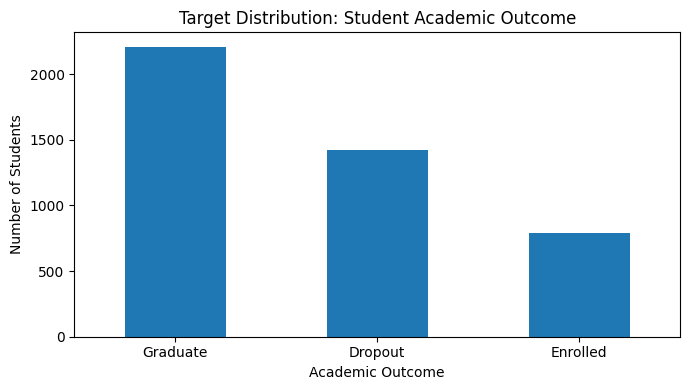

In [15]:
# Target distribution chart

import matplotlib.pyplot as plt

target_overview.plot(
    x="Academic Outcome",
    y="Student Count",
    kind="bar",
    legend=False,
    figsize=(7, 4)
)

plt.title("Target Distribution: Student Academic Outcome")
plt.xlabel("Academic Outcome")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [16]:
# Model-readiness note:
# The second-semester academic columns are powerful predictors,
# but if the goal is very early dropout prediction, they may not be available yet.
# So we can later compare two modeling scenarios.

prediction_scenarios = pd.DataFrame({
    "Scenario": [
        "Full academic-record prediction",
        "Early-risk prediction"
    ],
    "Features Used": [
        "Admission, demographic, financial, first-semester, second-semester, and economic features",
        "Admission, demographic, financial, and possibly first-semester features only"
    ],
    "Use Case": [
        "Predict final academic outcome using all available student records",
        "Identify students at risk earlier so the university can intervene sooner"
    ],
    "Important Note": [
        "Usually gives stronger predictive performance",
        "More realistic for early intervention, but may be harder"
    ]
})

display(prediction_scenarios)


,Scenario,Features Used,Use Case,Important Note
0,Full academic-record prediction,"Admission, demographic, financial, first-semes...",Predict final academic outcome using all avail...,Usually gives stronger predictive performance
1,Early-risk prediction,"Admission, demographic, financial, and possibl...",Identify students at risk earlier so the unive...,"More realistic for early intervention, but may..."


In [17]:
# Presentation-ready dataset overview text

dataset_overview_text = f'''
## Dataset Overview

The dataset is a tabular educational dataset where each row represents one student.
It contains **{df.shape[0]:,} student records**, **{df.shape[1] - 1} input features**, and one target column named **{TARGET_COLUMN}**.

The target variable classifies students into three academic outcomes:
**Graduate**, **Dropout**, and **Enrolled**.

The features cover multiple dimensions of student information:
admission and course information, demographic and family background, financial indicators,
first-semester academic performance, second-semester academic performance, and macroeconomic context.

The dataset is already clean at a basic quality level because it has **{df.isna().sum().sum():,} missing values**
and **{df.duplicated().sum():,} duplicate rows**. However, preprocessing is still required because many numeric columns
represent encoded categories and should be handled carefully during modeling.
'''

display(Markdown(dataset_overview_text))



## Dataset Overview

The dataset is a tabular educational dataset where each row represents one student.
It contains **4,424 student records**, **36 input features**, and one target column named **Target**.

The target variable classifies students into three academic outcomes:
**Graduate**, **Dropout**, and **Enrolled**.

The features cover multiple dimensions of student information:
admission and course information, demographic and family background, financial indicators,
first-semester academic performance, second-semester academic performance, and macroeconomic context.

The dataset is already clean at a basic quality level because it has **0 missing values**
and **0 duplicate rows**. However, preprocessing is still required because many numeric columns
represent encoded categories and should be handled carefully during modeling.
